# Instruções por consumidor — `instruction-what-for.png` (Seção 4.2.2)

Mesmo gráfico de `graphic/instruction/grafico_tipo_instrucao.ipynb`. Os números vêm das colunas *Instruction format* e *Instruction consumer* de `../data/tabela_de_codigos_artefatos.csv`: barras por formato da instrução, empilhadas por consumidor.

In [1]:
import sys
sys.path.insert(0, "../scripts")   # graficos/scripts: dados_artefatos.py, paleta_grupos.py

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import dados_artefatos as da
from paleta_grupos import tons_grupo, CINZA_OUTROS, CINZA_INDEFINIDO

# família azul do grupo instruction: três tons bem separados (claro, médio, escuro)
cor_determ, cor_manual, cor_llm = tons_grupo("instruction", 3, inicio=0.22)

In [2]:
# Estudos por formato da instrução, separados por consumidor
# (manual = execução manual, llm = consumida por LLM, ferramenta = ferramenta determinística)
rotulos = {"IF1": "Test scenarios\n(natural language)", "IF2": "Tabular / structured\ntest case", "IF3": "Gherkin / BDD",
           "IF4": "Textual\nrecommendations", "IF5": "Test plan", "IF6": "State diagram /\nmodel", "IF7": "Other"}
tabela = da.cruzamento("Instruction format", "Instruction consumer")
ordem = sorted([c for c in rotulos if c != "IF7"], key=lambda c: -tabela.loc[c].sum()) + ["IF7"]   # decrescente, "Other" no fim
dados = [{"tipo": rotulos[c], "manual": int(tabela.loc[c, "IC1"]), "llm": int(tabela.loc[c, "IC2"]),
          "ferramenta": int(tabela.loc[c, "IC3"])} for c in ordem]

consumidores = [
    ("manual", cor_manual, "For manual execution"),
    ("llm", cor_llm, "For LLM"),
    ("ferramenta", cor_determ, "Deterministic tool"),
]

x_pos = range(len(dados))
totais_cons = {k: sum(d[k] for d in dados) for k, _, _ in consumidores}
total = sum(totais_cons.values())
print(totais_cons, "total =", total)
assert total == len(da.estudos("Instruction format"))

{'manual': 42, 'llm': 17, 'ferramenta': 7} total = 66


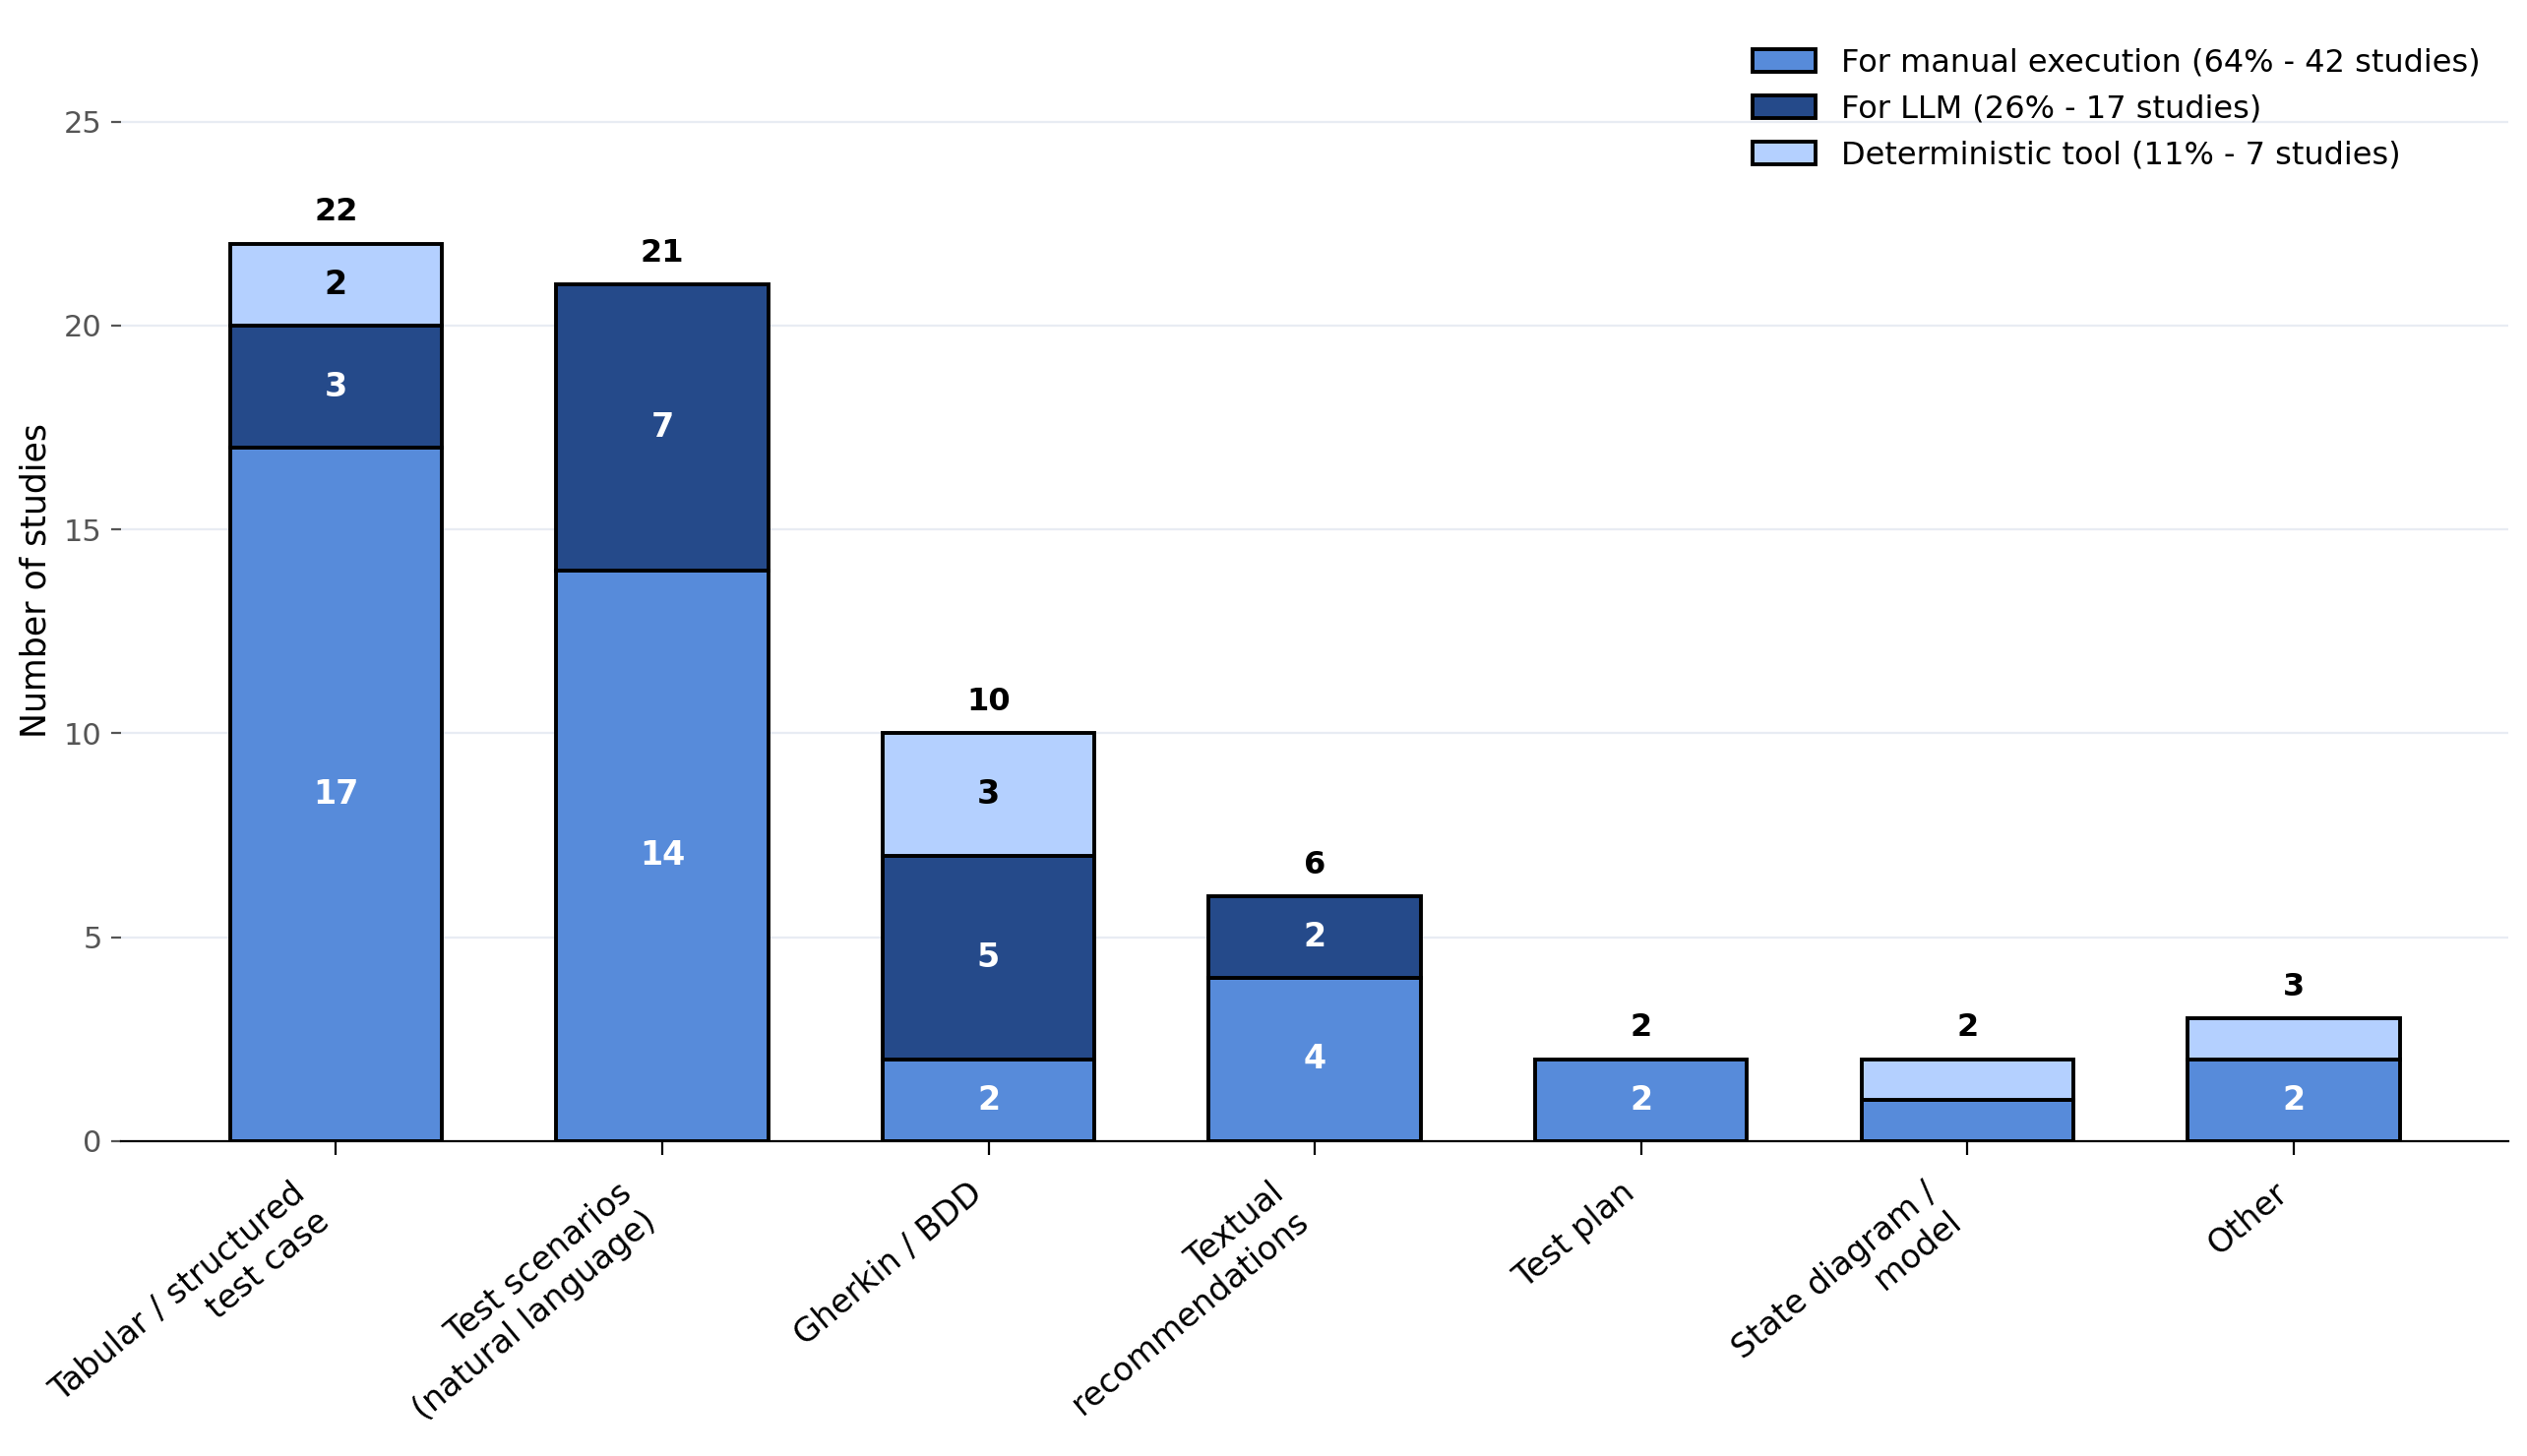

In [3]:
def cor_texto_legivel(hex_cor):
    r, g, b = (int(hex_cor[i : i + 2], 16) for i in (1, 3, 5))
    luminancia = 0.299 * r + 0.587 * g + 0.114 * b
    return "black" if luminancia > 150 else "white"

fig, ax = plt.subplots(figsize=(13, 7.5), dpi=200)

for x, d in zip(x_pos, dados):
    base = 0
    for chave, cor, _ in consumidores:
        v = d[chave]
        if v == 0:
            continue
        ax.bar(x, v, bottom=base, color=cor, width=0.65, edgecolor="black", linewidth=1.4, zorder=3)
        # número dentro do segmento só quando cabe (segmentos de 1 ficam sem rótulo)
        if v >= 2:
            ax.text(x, base + v / 2, str(v), ha="center", va="center", fontsize=12,
                    fontweight="bold", color=cor_texto_legivel(cor), zorder=4)
        base += v
    ax.text(x, base + 0.4, str(base), ha="center", va="bottom", fontsize=11.5,
            fontweight="bold", color="black")

ax.set_xticks(list(x_pos))
ax.set_xticklabels([d["tipo"] for d in dados], rotation=40, ha="right", fontsize=12)

ax.set_ylim(0, max(d["manual"] + d["llm"] + d["ferramenta"] for d in dados) * 1.25)
ax.set_ylabel("Number of studies", fontsize=12.5)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("black")
ax.tick_params(axis="x", length=5, pad=8, color="black")
ax.tick_params(axis="y", colors="#555555", labelsize=11)
ax.yaxis.grid(True, color="#e8ecf3", zorder=0)
ax.set_axisbelow(True)

legend_handles = [
    Patch(facecolor=cor, edgecolor="black", linewidth=1.4,
          label=f"{nome} ({totais_cons[k] / total:.0%} - {totais_cons[k]} studies)")
    for k, cor, nome in consumidores
]
ax.legend(handles=legend_handles, loc="upper right", frameon=False, fontsize=11.5)

plt.tight_layout()
plt.savefig("instruction-what-for.png", bbox_inches="tight", dpi=200)
plt.savefig("instruction-what-for.pdf", bbox_inches="tight")
plt.show()